In [1]:

import os

train_path = "../data/raw/archive/Train"
val_path = "../data/raw/archive/Val"

classes = os.listdir(train_path)

print("Classes:", classes)


Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [2]:
print("Training Dataset:")

for classe in classes:
    folder = os.path.join(train_path, classe, "images")

    images = os.listdir(folder)

    print(classe, ":", len(images))


Training Dataset:
Glioma : 1153
Meningioma : 1449
No Tumor : 711
Pituitary : 1424


In [3]:
print("Validation Dataset:")

for classe in classes:
    folder = os.path.join(val_path, classe, "images")

    images = os.listdir(folder)

    print(classe, ":", len(images))


Validation Dataset:
Glioma : 136
Meningioma : 140
No Tumor : 100
Pituitary : 136


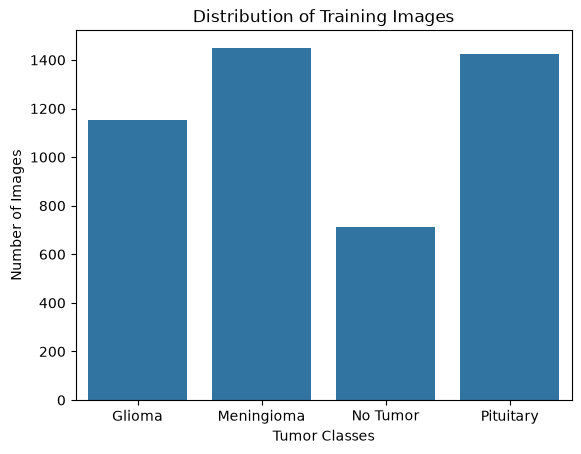

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = []

for classe in classes:
    folder = os.path.join(train_path, classe, "images")

    for image in os.listdir(folder):
        if image.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            labels.append(classe)

sns.countplot(x=labels)

plt.title("Distribution of Training Images")
plt.xlabel("Tumor Classes")
plt.ylabel("Number of Images")
plt.show()


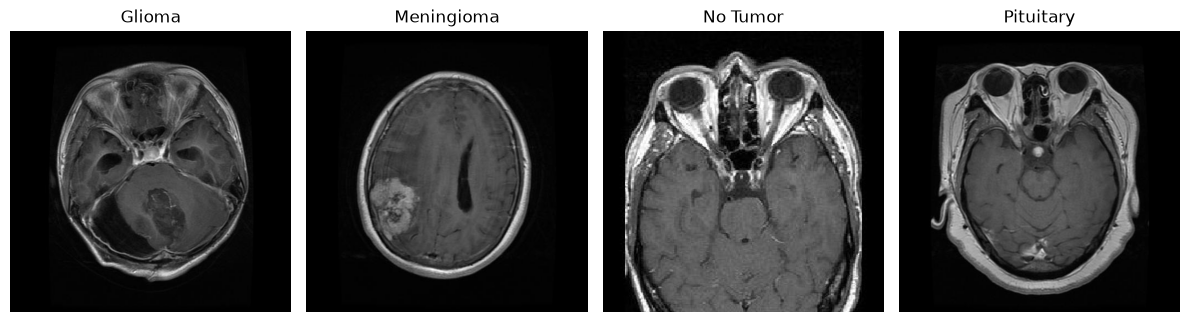

In [5]:
from PIL import Image

plt.figure(figsize=(12, 4))

for i, classe in enumerate(classes):

    folder = os.path.join(train_path, classe, "images")

    images = os.listdir(folder)
    image_path = os.path.join(folder, images[0])

    image = Image.open(image_path)

    plt.subplot(1, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()
plt.savefig("mri_class_samples.png")
plt.show()


In [6]:
extensions = (".jpg", ".jpeg", ".png", ".bmp")

for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "images")

        valid = 0
        invalid = 0

        for filename in os.listdir(folder):

            file_path = os.path.join(folder, filename)

            if not os.path.isfile(file_path):
                continue

            if not filename.lower().endswith(extensions):
                invalid += 1
                print("Invalid extension:", filename)
                continue

            try:
                with Image.open(file_path) as image:
                    image.load()

                valid += 1

            except (OSError, ValueError):
                invalid += 1
                print("Corrupted image:", filename)

        print(classe, "- Valid:", valid, "- Invalid:", invalid)



Dataset: ../data/raw/archive/Train
Glioma - Valid: 1153 - Invalid: 0
Meningioma - Valid: 1449 - Invalid: 0
No Tumor - Valid: 711 - Invalid: 0
Pituitary - Valid: 1424 - Invalid: 0

Dataset: ../data/raw/archive/Val
Glioma - Valid: 136 - Invalid: 0
Meningioma - Valid: 140 - Invalid: 0
No Tumor - Valid: 100 - Invalid: 0
Pituitary - Valid: 136 - Invalid: 0


In [7]:
for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        images_folder = os.path.join(dataset_path, classe, "images")
        labels_folder = os.path.join(dataset_path, classe, "labels")

        images = os.listdir(images_folder)
        labels = os.listdir(labels_folder)

        image_names = set()

        for image in images:
            name = os.path.splitext(image)[0]
            image_names.add(name)

        label_names = set()

        for label in labels:
            if label.endswith(".txt"):
                name = os.path.splitext(label)[0]
                label_names.add(name)

        matched = image_names & label_names
        missing = image_names - label_names
        extra = label_names - image_names

        print(classe)
        print("Matched:", len(matched))
        print("Images without labels:", len(missing))
        print("Labels without images:", len(extra))



Dataset: ../data/raw/archive/Train
Glioma
Matched: 1153
Images without labels: 0
Labels without images: 0
Meningioma
Matched: 1449
Images without labels: 0
Labels without images: 0
No Tumor
Matched: 711
Images without labels: 0
Labels without images: 0
Pituitary
Matched: 1424
Images without labels: 0
Labels without images: 0

Dataset: ../data/raw/archive/Val
Glioma
Matched: 136
Images without labels: 0
Labels without images: 0
Meningioma
Matched: 140
Images without labels: 0
Labels without images: 0
No Tumor
Matched: 98
Images without labels: 2
Labels without images: 2
Pituitary
Matched: 136
Images without labels: 0
Labels without images: 0


In [8]:
for classe in classes:

    folder = os.path.join(train_path, classe, "labels")

    files = os.listdir(folder)

    print("\nClass:", classe)

    for filename in files:

        if filename.endswith(".txt"):

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                content = file.read()

            print("Filename:", filename)
            print("Content:", content)

            break



Class: Glioma
Filename: Te-glTr_0000.txt
Content: 0 0.555664 0.653320 0.146484 0.193359


Class: Meningioma
Filename: Tr-meTr_0008.txt
Content: 1 0.313477 0.631836 0.193359 0.240234


Class: No Tumor
Filename: 1.txt
Content: 2 0.502857 0.675714 0.851429 0.648571


Class: Pituitary
Filename: Te-pi_0010.txt
Content: 3 0.494141 0.431641 0.046875 0.039062



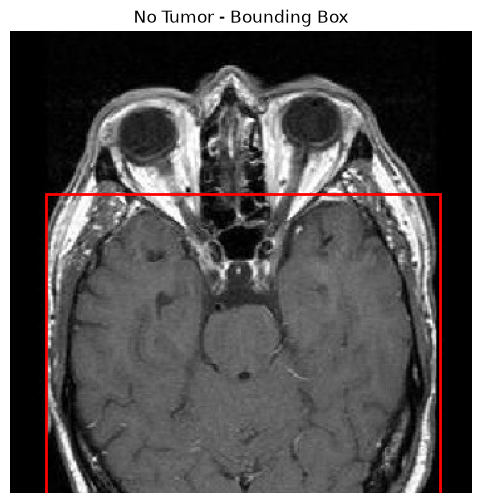

In [9]:
from PIL import Image
from matplotlib.patches import Rectangle

classe = "No Tumor"
filename = "1"

image_folder = os.path.join(train_path, classe, "images")
label_path = os.path.join(train_path, classe, "labels", filename + ".txt")

# Find the matching image
image_path = None

for image_name in os.listdir(image_folder):
    name = os.path.splitext(image_name)[0]

    if name == filename:
        image_path = os.path.join(image_folder, image_name)
        break

# Open the image
image = Image.open(image_path)
width, height = image.size

# Read the annotation
with open(label_path, "r") as file:
    values = file.readline().split()

class_id = int(values[0])
x, y, w, h = map(float, values[1:])

# Convert normalized values into pixels
box_width = w * width
box_height = h * height

x_min = (x * width) - box_width / 2
y_min = (y * height) - box_height / 2

# Display the image
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray")

box = Rectangle(
    (x_min, y_min),
    box_width,
    box_height,
    fill=False,
    edgecolor="red",
    linewidth=2
)

ax.add_patch(box)
ax.set_title("No Tumor - Bounding Box")
ax.axis("off")

plt.show()


In [10]:
for dataset_path in [train_path, val_path]:

    folder = os.path.join(dataset_path, "No Tumor", "labels")

    empty = 0
    not_empty = 0

    for filename in os.listdir(folder):

        if filename.endswith(".txt"):

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                content = file.read().strip()

            if content == "":
                empty += 1
            else:
                not_empty += 1

    print("\nDataset:", dataset_path)
    print("Empty annotations:", empty)
    print("Non-empty annotations:", not_empty)



Dataset: ../data/raw/archive/Train
Empty annotations: 0
Non-empty annotations: 711

Dataset: ../data/raw/archive/Val
Empty annotations: 0
Non-empty annotations: 100


In [11]:

valid = 0
invalid = 0

for dataset_path in [train_path, val_path]:
    for classe in classes:

        folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(folder):

            if not filename.endswith(".txt"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                lines = file.readlines()

            for line in lines:

                values = line.split()

                try:
                    if len(values) != 5:
                        raise ValueError("Wrong number of values")

                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                    if class_id not in [0, 1, 2, 3]:
                        raise ValueError("Invalid class ID")

                    if not (0 <= x <= 1 and 0 <= y <= 1):
                        raise ValueError("Invalid center")

                    if not (0 < w <= 1 and 0 < h <= 1):
                        raise ValueError("Invalid box size")

                    if x - w / 2 < -0.00001 or x + w / 2 > 1.00001:
                        raise ValueError("Box outside image")

                    if y - h / 2 < -0.00001 or y + h / 2 > 1.00001:
                        raise ValueError("Box outside image")

                    valid += 1

                except ValueError as error:
                    invalid += 1
                    print("Invalid:", filename, "-", error)

print("\nValid annotations:", valid)
print("Invalid annotations:", invalid)



Valid annotations: 5873
Invalid annotations: 0


In [12]:

class_ids = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3
}

correct = 0
mismatch = 0

for dataset_path in [train_path, val_path]:

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(folder):

            if not filename.endswith(".txt"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                lines = file.readlines()

            for line in lines:

                values = line.split()

                if not values:
                    continue

                label_id = int(values[0])

                if label_id == class_ids[classe]:
                    correct += 1
                else:
                    mismatch += 1
                    print("Mismatch:", classe, filename)

print("Correct labels:", correct)
print("Mismatched labels:", mismatch)


Mismatch: Glioma Te-gl_0036.txt
Mismatch: Glioma Te-gl_0041.txt
Mismatch: Glioma Te-gl_0042.txt
Mismatch: Glioma Te-gl_0043.txt
Mismatch: Glioma Te-gl_0048.txt
Mismatch: Glioma Te-gl_0060.txt
Mismatch: Glioma Te-gl_0061.txt
Mismatch: Glioma Te-gl_0065.txt
Mismatch: Glioma Te-gl_0067.txt
Mismatch: Glioma Te-gl_0122.txt
Mismatch: Glioma Te-gl_0129.txt
Mismatch: Glioma Te-gl_0138.txt
Mismatch: Glioma Te-gl_0142.txt
Mismatch: Glioma Tr-gl_0115.txt
Mismatch: Glioma Tr-gl_0121.txt
Mismatch: Glioma Tr-gl_0265.txt
Mismatch: Glioma Tr-gl_0461.txt
Mismatch: Glioma Tr-gl_0470.txt
Mismatch: Glioma Tr-gl_0471.txt
Mismatch: Glioma Tr-gl_0473.txt
Mismatch: Glioma Tr-gl_0483.txt
Mismatch: Glioma Tr-gl_0484.txt
Mismatch: Glioma Tr-gl_0485.txt
Mismatch: Glioma Tr-gl_0486.txt
Mismatch: Glioma Tr-gl_0487.txt
Mismatch: Glioma Tr-gl_0499.txt
Mismatch: Glioma Tr-gl_0500.txt
Mismatch: Glioma Tr-gl_0501.txt
Mismatch: Glioma Tr-gl_0502.txt
Mismatch: Glioma Tr-gl_0564.txt
Mismatch: Glioma Tr-gl_0565.txt
Mismatch

In [13]:

for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "labels")

        counts = {0: 0, 1: 0, 2: 0, 3: 0}

        for filename in os.listdir(folder):

            if not filename.endswith(".txt"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                for line in file:

                    values = line.split()

                    if values:
                        class_id = int(values[0])
                        counts[class_id] += 1

        print(classe, ":", counts)



Dataset: ../data/raw/archive/Train
Glioma : {0: 1347, 1: 3, 2: 0, 3: 152}
Meningioma : {0: 2, 1: 1478, 2: 0, 3: 103}
No Tumor : {0: 0, 1: 0, 2: 711, 3: 0}
Pituitary : {0: 0, 1: 1, 2: 0, 3: 1520}

Dataset: ../data/raw/archive/Val
Glioma : {0: 153, 1: 0, 2: 0, 3: 12}
Meningioma : {0: 0, 1: 142, 2: 0, 3: 6}
No Tumor : {0: 0, 1: 0, 2: 100, 3: 0}
Pituitary : {0: 0, 1: 0, 2: 0, 3: 143}


Detected annotation class ID: 3
Detected annotation class ID: 1


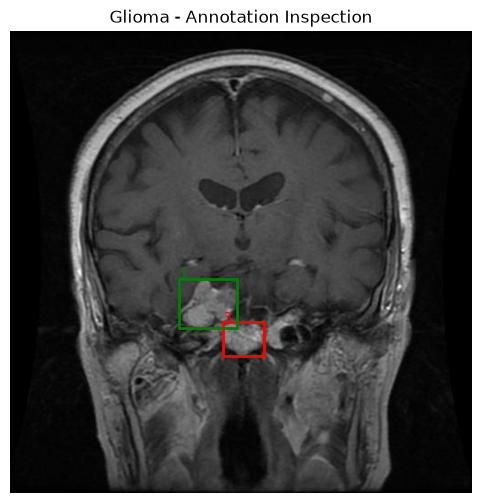

In [14]:
classe = "Meningioma"
filename = "m (45)"

# Find which dataset contains the annotation
dataset_path = train_path

label_path = os.path.join(dataset_path, classe, "labels", filename + ".txt")

if not os.path.exists(label_path):
    dataset_path = val_path
    label_path = os.path.join(dataset_path, classe, "labels", filename + ".txt")

# Find the corresponding image
images_folder = os.path.join(dataset_path, classe, "images")

image_path = None

for image_name in os.listdir(images_folder):
    if os.path.splitext(image_name)[0] == filename:
        image_path = os.path.join(images_folder, image_name)
        break

# Open the image
image = Image.open(image_path)
width, height = image.size

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray")

# Read and display every bounding box
with open(label_path, "r") as file:

    for line in file:
        values = line.split()

        class_id = int(values[0])
        x, y, w, h = map(float, values[1:])

        box_width = w * width
        box_height = h * height

        x_min = x * width - box_width / 2
        y_min = y * height - box_height / 2

        color = "green" if class_id == 1 else "red"

        box = Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            fill=False,
            edgecolor=color,
            linewidth=2
        )

        ax.add_patch(box)
        ax.text(x_min, y_min, str(class_id), color=color)

        print("Detected annotation class ID:", class_id)

plt.title("Glioma - Annotation Inspection")
plt.axis("off")
plt.show()


In [15]:
import hashlib

image_hashes = {}
duplicates = []

for dataset_path in [train_path, val_path]:

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "images")

        for filename in os.listdir(folder):

            path = os.path.join(folder, filename)

            with open(path, "rb") as file:
                content = file.read()

            image_hash = hashlib.md5(content).hexdigest()

            if image_hash in image_hashes:
                duplicates.append((path, image_hashes[image_hash]))
            else:
                image_hashes[image_hash] = path

print("Duplicate image files:", len(duplicates))

for duplicate in duplicates[:5]:
    print(duplicate)


Duplicate image files: 1336
('../data/raw/archive/Train/Glioma/images/gg (184).jpg', '../data/raw/archive/Train/Glioma/images/gg (162).jpg')
('../data/raw/archive/Train/Glioma/images/gg (2).jpg', '../data/raw/archive/Train/Glioma/images/gg (126).jpg')
('../data/raw/archive/Train/Glioma/images/gg (272).jpg', '../data/raw/archive/Train/Glioma/images/Tr-glTr_0000.jpg')
('../data/raw/archive/Train/Glioma/images/gg (284).jpg', '../data/raw/archive/Train/Glioma/images/Tr-glTr_0003.jpg')
('../data/raw/archive/Train/Glioma/images/gg (294).jpg', '../data/raw/archive/Train/Glioma/images/gg (289).jpg')


In [16]:
image_hashes = {}
duplicates_between_sets = 0
different_classes = 0

for dataset_path in [train_path, val_path]:

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "images")

        for filename in os.listdir(folder):

            path = os.path.join(folder, filename)

            with open(path, "rb") as file:
                content = file.read()

            image_hash = hashlib.md5(content).hexdigest()

            if image_hash in image_hashes:

                old_dataset, old_classe = image_hashes[image_hash]

                if old_dataset != dataset_path:
                    duplicates_between_sets += 1

                if old_classe != classe:
                    different_classes += 1

            else:
                image_hashes[image_hash] = (dataset_path, classe)

print("Repeated files across datasets:", duplicates_between_sets)
print("Repeated files with different classes:", different_classes)


Repeated files across datasets: 218
Repeated files with different classes: 0


In [17]:
folder = os.path.join(val_path, "No Tumor", "labels")

for filename in os.listdir(folder):
    if "55" in filename:
        print(repr(filename))


In [18]:

images_folder = os.path.join(val_path, "No Tumor", "images")
labels_folder = os.path.join(val_path, "No Tumor", "labels")

images = os.listdir(images_folder)
labels = os.listdir(labels_folder)

print("Images containing 55:")
for image in images:
    if "55" in image:
        print(image)

print("\nTotal images:", len(images))
print("Total labels:", len(labels))


Images containing 55:
image(55).jpg

Total images: 100
Total labels: 100


In [19]:

image_names = set()

for image in images:
    name = os.path.splitext(image)[0]
    image_names.add(name)

label_names = set()

for label in labels:
    name = os.path.splitext(label)[0]
    label_names.add(name)

missing = image_names - label_names
extra = label_names - image_names

print("Images without labels:", missing)
print("Labels without images:", extra)


Images without labels: {'image(61)', 'image(55)'}
Labels without images: {'image(53)', 'image(60)'}


In [20]:

total_missing = 0
total_extra = 0

for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        images_folder = os.path.join(dataset_path, classe, "images")
        labels_folder = os.path.join(dataset_path, classe, "labels")

        images = os.listdir(images_folder)
        labels = os.listdir(labels_folder)

        image_names = set()

        for image in images:
            if image.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                image_names.add(os.path.splitext(image)[0])

        label_names = set()

        for label in labels:
            if label.lower().endswith(".txt"):
                label_names.add(os.path.splitext(label)[0])

        missing = image_names - label_names
        extra = label_names - image_names

        total_missing += len(missing)
        total_extra += len(extra)

        print(classe)
        print("  Missing labels:", len(missing))
        print("  Extra labels:", len(extra))

print("\nTotal images without labels:", total_missing)
print("Total labels without images:", total_extra)



Dataset: ../data/raw/archive/Train
Glioma
  Missing labels: 0
  Extra labels: 0
Meningioma
  Missing labels: 0
  Extra labels: 0
No Tumor
  Missing labels: 0
  Extra labels: 0
Pituitary
  Missing labels: 0
  Extra labels: 0

Dataset: ../data/raw/archive/Val
Glioma
  Missing labels: 0
  Extra labels: 0
Meningioma
  Missing labels: 0
  Extra labels: 0
No Tumor
  Missing labels: 2
  Extra labels: 2
Pituitary
  Missing labels: 0
  Extra labels: 0

Total images without labels: 2
Total labels without images: 2


In [21]:
image_hashes = {}

same_labels = 0
different_labels = 0
missing_labels = 0

for dataset_path in [train_path, val_path]:

    for classe in classes:

        images_folder = os.path.join(dataset_path, classe, "images")
        labels_folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(images_folder):

            image_path = os.path.join(images_folder, filename)

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            name = os.path.splitext(filename)[0]
            label_path = os.path.join(labels_folder, name + ".txt")

            if not os.path.exists(label_path):
                missing_labels += 1
                continue

            with open(label_path, "r") as file:
                label_content = file.read().strip()

            if image_hash in image_hashes:

                if image_hashes[image_hash] == label_content:
                    same_labels += 1
                else:
                    different_labels += 1

            else:
                image_hashes[image_hash] = label_content

print("Duplicates with identical labels:", same_labels)
print("Duplicates with different labels:", different_labels)
print("Missing labels:", missing_labels)


Duplicates with identical labels: 5
Duplicates with different labels: 1331
Missing labels: 2


In [22]:
seen = {}
found = False

for dataset_path in [train_path, val_path]:

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "images")

        for filename in os.listdir(folder):

            image_path = os.path.join(folder, filename)

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            name = os.path.splitext(filename)[0]

            label_path = os.path.join(
                dataset_path, classe, "labels", name + ".txt"
            )

            if not os.path.exists(label_path):
                continue

            with open(label_path, "r") as file:
                label_text = file.read().strip()

            if image_hash in seen:

                old_path, old_label = seen[image_hash]

                if old_label != label_text:

                    print("First image:", old_path)
                    print("First annotation:", old_label)

                    print("\nSecond image:", image_path)
                    print("Second annotation:", label_text)

                    found = True
                    break

            else:
                seen[image_hash] = (image_path, label_text)

        if found:
            break

    if found:
        break


First image: ../data/raw/archive/Train/Glioma/images/gg (162).jpg
First annotation: 0 0.564453 0.307617 0.109375 0.115234

Second image: ../data/raw/archive/Train/Glioma/images/gg (184).jpg
Second annotation: 0 0.568359 0.305664 0.117188 0.111328


In [23]:

seen = {}

same_classes = 0
different_classes = 0

for dataset_path in [train_path, val_path]:
    for classe in classes:

        images_folder = os.path.join(dataset_path, classe, "images")
        labels_folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(images_folder):

            image_path = os.path.join(images_folder, filename)

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            name = os.path.splitext(filename)[0]
            label_path = os.path.join(labels_folder, name + ".txt")

            if not os.path.exists(label_path):
                continue

            with open(label_path, "r") as file:
                lines = file.read().strip().splitlines()

            class_ids = sorted(int(line.split()[0]) for line in lines)

            if image_hash in seen:
                if seen[image_hash] == class_ids:
                    same_classes += 1
                else:
                    different_classes += 1
            else:
                seen[image_hash] = class_ids

print("Duplicates with same class IDs:", same_classes)
print("Duplicates with different class IDs:", different_classes)


Duplicates with same class IDs: 1243
Duplicates with different class IDs: 93


In [24]:

seen = {}
examples = []

for dataset_path in [train_path, val_path]:
    for classe in classes:

        images_folder = os.path.join(dataset_path, classe, "images")
        labels_folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(images_folder):

            image_path = os.path.join(images_folder, filename)

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            name = os.path.splitext(filename)[0]
            label_path = os.path.join(labels_folder, name + ".txt")

            if not os.path.exists(label_path):
                continue

            with open(label_path, "r") as file:
                label_text = file.read().strip()

            class_ids = sorted(
                int(line.split()[0])
                for line in label_text.splitlines()
            )

            if image_hash in seen:
                old_path, old_classes, old_label = seen[image_hash]

                if old_classes != class_ids:
                    examples.append((
                        old_path, old_classes, old_label,
                        image_path, class_ids, label_text
                    ))
            else:
                seen[image_hash] = (image_path, class_ids, label_text)

for example in examples[:5]:
    print("\n--- DUPLICATE PAIR ---")
    print("First image:", example[0])
    print("Class IDs:", example[1])
    print("Annotation:", example[2])

    print("Second image:", example[3])
    print("Class IDs:", example[4])
    print("Annotation:", example[5])



--- DUPLICATE PAIR ---
First image: ../data/raw/archive/Train/Glioma/images/Tr-gl_0026.jpg
Class IDs: [0]
Annotation: 0 0.533203 0.489258 0.156250 0.185547
Second image: ../data/raw/archive/Train/Glioma/images/gg (376).jpg
Class IDs: [0, 0]
Annotation: 0 0.533203 0.487305 0.152344 0.181641
0 0.549805 0.337891 0.107422 0.105469

--- DUPLICATE PAIR ---
First image: ../data/raw/archive/Train/Glioma/images/Tr-gl_0032.jpg
Class IDs: [0]
Annotation: 0 0.364258 0.308594 0.236328 0.277344
Second image: ../data/raw/archive/Train/Glioma/images/gg (400).jpg
Class IDs: [0, 3]
Annotation: 0 0.368164 0.311523 0.228516 0.271484
3 0.484375 0.734375 0.085938 0.035156

--- DUPLICATE PAIR ---
First image: ../data/raw/archive/Train/Glioma/images/Tr-gl_0036.jpg
Class IDs: [0]
Annotation: 0 0.420898 0.327148 0.099609 0.138672
Second image: ../data/raw/archive/Train/Glioma/images/gg (416).jpg
Class IDs: [0, 0]
Annotation: 0 0.417969 0.328125 0.097656 0.136719
0 0.514648 0.369141 0.068359 0.074219

--- DUPLI

In [25]:
unique_images = {}
conflicts = []

for dataset_path in [train_path, val_path]:
    for classe in classes:

        folder = os.path.join(dataset_path, classe, "images")

        for filename in sorted(os.listdir(folder)):

            image_path = os.path.join(folder, filename)

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                continue

            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            if image_hash not in unique_images:
                unique_images[image_hash] = (image_path, classe)

            elif unique_images[image_hash][1] != classe:
                conflicts.append(image_path)

print("Unique images:", len(unique_images))
print("Conflicting image classes:", len(conflicts))

for classe in classes:
    count = sum(
        1 for path, label in unique_images.values()
        if label == classe
    )
    print(classe, ":", count)


Unique images: 3913
Conflicting image classes: 0
Glioma : 1190
Meningioma : 1095
No Tumor : 601
Pituitary : 1027


In [26]:

from sklearn.model_selection import train_test_split
from collections import Counter

# Convert our dictionary into a list of (path, class) pairs
data = list(unique_images.values())

# First split: 70% training, 30% remaining
train_data, remaining_data = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=[label for path, label in data]
)

# Second split: half validation, half testing
val_data, test_data = train_test_split(
    remaining_data,
    test_size=0.50,
    random_state=42,
    stratify=[label for path, label in remaining_data]
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

print("\nTraining classes:", Counter(label for path, label in train_data))
print("Validation classes:", Counter(label for path, label in val_data))
print("Testing classes:", Counter(label for path, label in test_data))


Training images: 2739
Validation images: 587
Testing images: 587

Training classes: Counter({'Glioma': 833, 'Meningioma': 766, 'Pituitary': 719, 'No Tumor': 421})
Validation classes: Counter({'Glioma': 178, 'Meningioma': 165, 'Pituitary': 154, 'No Tumor': 90})
Testing classes: Counter({'Glioma': 179, 'Meningioma': 164, 'Pituitary': 154, 'No Tumor': 90})


In [27]:

# Get image paths from each subset
train_paths = set(path for path, label in train_data)
val_paths = set(path for path, label in val_data)
test_paths = set(path for path, label in test_data)

# Check whether any paths appear in multiple subsets
train_val_overlap = train_paths & val_paths
train_test_overlap = train_paths & test_paths
val_test_overlap = val_paths & test_paths

print("Train / Validation overlap:", len(train_val_overlap))
print("Train / Test overlap:", len(train_test_overlap))
print("Validation / Test overlap:", len(val_test_overlap))

# Verify all unique images have been included
print("\nTotal split images:",
      len(train_data) + len(val_data) + len(test_data))

print("Expected unique images:", len(unique_images))


Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

Total split images: 3913
Expected unique images: 3913


In [28]:
import csv

rows = []

splits = [
    ("train", train_data),
    ("val", val_data),
    ("test", test_data)
]

for split_name, images in splits:

    for image_path, classe in images:

        with open(image_path, "rb") as file:
            image_hash = hashlib.md5(file.read()).hexdigest()

        rows.append({
            "split": split_name,
            "class": classe,
            "image_path": os.path.relpath(image_path, ".."),
            "hash": image_hash
        })

# Check for duplicate images between subsets
hash_sets = {}

for split_name, images in splits:
    hash_sets[split_name] = {
        row["hash"] for row in rows
        if row["split"] == split_name
    }

assert not (hash_sets["train"] & hash_sets["val"])
assert not (hash_sets["train"] & hash_sets["test"])
assert not (hash_sets["val"] & hash_sets["test"])

# Save the CSV
output_folder = "../data/processed"
os.makedirs(output_folder, exist_ok=True)

csv_path = os.path.join(
    output_folder, "classification_split.csv"
)

with open(csv_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["split", "class", "image_path", "hash"]
    )
    writer.writeheader()
    writer.writerows(rows)

print("CSV saved:", csv_path)
print("Total rows:", len(rows))
print("Exact-image overlap check: passed")


CSV saved: ../data/processed/classification_split.csv
Total rows: 3913
Exact-image overlap check: passed


In [29]:
csv_path = "../data/processed/classification_split.csv"

with open(csv_path, "r", encoding="utf-8") as file:
    rows = list(csv.DictReader(file))

missing_paths = []

for row in rows:
    image_path = os.path.join("..", row["image_path"])

    if not os.path.isfile(image_path):
        missing_paths.append(image_path)

print("CSV rows:", len(rows))
print("Split counts:", dict(Counter(row["split"] for row in rows)))
print("Unique hashes:", len(set(row["hash"] for row in rows)))
print("Missing image paths:", len(missing_paths))

print("First missing paths:", missing_paths[:5])


CSV rows: 3913
Split counts: {'train': 2739, 'val': 587, 'test': 587}
Unique hashes: 3913
Missing image paths: 0
First missing paths: []


In [30]:
sizes = Counter()
modes = Counter()

for image_path, classe in train_data:
    with Image.open(image_path) as image:
        sizes[image.size] += 1
        modes[image.mode] += 1

print("Most common image sizes:")
print(sizes.most_common(10))

print("\nImage color modes:")
print(modes)


Most common image sizes:
[((512, 512), 2210), ((225, 225), 71), ((630, 630), 38), ((442, 442), 22), ((201, 251), 15), ((201, 250), 13), ((236, 236), 13), ((256, 256), 11), ((468, 444), 11), ((214, 236), 8)]

Image color modes:
Counter({'RGB': 2025, 'L': 710, 'RGBA': 3, 'P': 1})


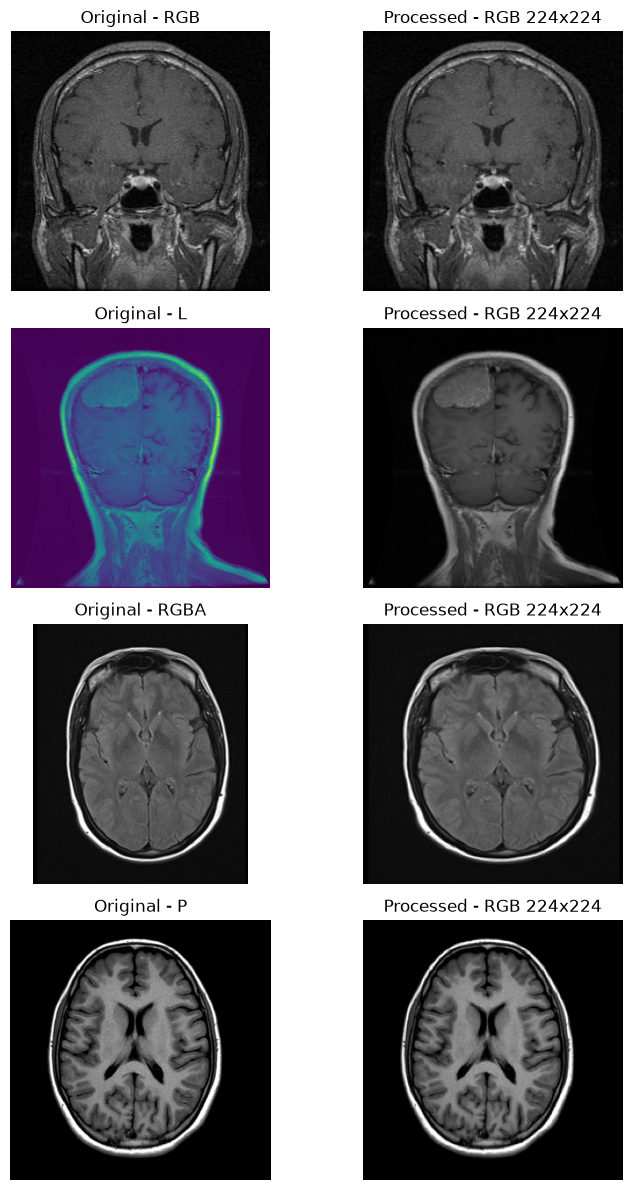

In [31]:
# Keep one example of each image mode
examples = {}

for image_path, classe in train_data:
    with Image.open(image_path) as image:
        if image.mode not in examples:
            examples[image.mode] = image_path

# Display original and processed images
fig, axes = plt.subplots(len(examples), 2, figsize=(8, 12))

for i, (mode, image_path) in enumerate(examples.items()):

    with Image.open(image_path) as image:
        original = image.copy()

    processed = original.convert("RGB")
    processed = processed.resize((224, 224))

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original - " + mode)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(processed)
    axes[i, 1].set_title("Processed - RGB 224x224")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [32]:

from PIL import Image, ImageOps
import numpy as np

def preprocess_image(image_path):
    with Image.open(image_path) as image:

        # Convert to RGB (3 channels)
        image = image.convert("RGB")

        # Resize while preserving proportions
        image = ImageOps.pad(
            image,
            (224, 224),
            method=Image.Resampling.BILINEAR,
            color=(0, 0, 0)
        )

        # Convert to a NumPy array
        image_array = np.array(image, dtype=np.float32)

    return image_array


Class: Pituitary
Shape: (224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 236.0


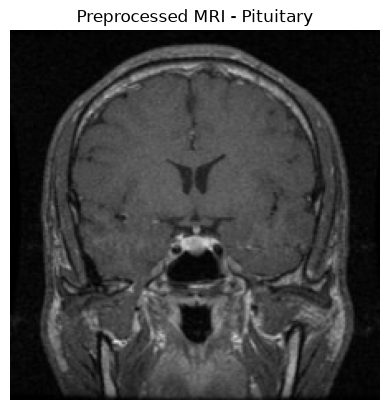

In [33]:

image_path, classe = train_data[0]

processed = preprocess_image(image_path)

print("Class:", classe)
print("Shape:", processed.shape)
print("Data type:", processed.dtype)
print("Minimum pixel value:", processed.min())
print("Maximum pixel value:", processed.max())

plt.imshow(processed.astype("uint8"))
plt.title("Preprocessed MRI - " + classe)
plt.axis("off")
plt.show()


In [34]:
for mode, image_path in examples.items():

    processed = preprocess_image(image_path)

    print("Original mode:", mode)
    print("Processed shape:", processed.shape)
    print("Data type:", processed.dtype)
    print("Pixel range:", processed.min(), "-", processed.max())
    print("---------------------------")


Original mode: RGB
Processed shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 236.0
---------------------------
Original mode: L
Processed shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 238.0
---------------------------
Original mode: RGBA
Processed shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 253.0
---------------------------
Original mode: P
Processed shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 255.0
---------------------------


In [35]:

import importlib.metadata as metadata

packages = [
    "tensorflow",
    "keras",
    "tensorflow-hub",
    "tf-keras"
]

for package in packages:
    try:
        version = metadata.version(package)
        print(package, ":", version)
    except metadata.PackageNotFoundError:
        print(package, ": Not installed")


tensorflow : Not installed
keras : Not installed
tensorflow-hub : Not installed
tf-keras : Not installed


In [36]:

import sys
import platform

print("Python version:", platform.python_version())
print("Python executable:", sys.executable)
print("Operating system:", platform.system())


Python version: 3.14.8
Python executable: /home/younessaj/PythonProjects/brain-tumor-ai/.venv/bin/python
Operating system: Linux


In [37]:

# Get one MRI image
image_path, classe = train_data[0]

# Apply our existing preprocessing
image = preprocess_image(image_path)

# Normalize pixel values
normalized_image = image / 255.0

print("Class:", classe)
print("Shape:", normalized_image.shape)
print("Minimum:", normalized_image.min())
print("Maximum:", normalized_image.max())
print("Data type:", normalized_image.dtype)


Class: Pituitary
Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 0.9254902
Data type: float32


In [38]:

def preprocess_for_model(image_path):

    # Use our existing preprocessing function
    image = preprocess_image(image_path)

    # Normalize pixel values to [0, 1]
    image = image / 255.0

    return image


# Test all four image formats
for mode, image_path in examples.items():

    image = preprocess_for_model(image_path)

    print(mode, ":", image.shape)
    print("Pixel range:", image.min(), "-", image.max())
    print("Data type:", image.dtype)
    print("--------------------")


RGB : (224, 224, 3)
Pixel range: 0.0 - 0.9254902
Data type: float32
--------------------
L : (224, 224, 3)
Pixel range: 0.0 - 0.93333334
Data type: float32
--------------------
RGBA : (224, 224, 3)
Pixel range: 0.0 - 0.99215686
Data type: float32
--------------------
P : (224, 224, 3)
Pixel range: 0.0 - 1.0
Data type: float32
--------------------


In [40]:
import sys
from pathlib import Path

# Find the project root (one folder above notebooks)
project_root = Path("..").resolve()

# Check that our file exists
print("Preprocessing file exists:",
      (project_root / "preprocessing.py").exists())

# Allow Python to import files from the project root
sys.path.insert(0, str(project_root))

# Import our preprocessing function
from preprocessing import preprocess_for_model

# Test it on an MRI image
image_path, classe = train_data[0]

image = preprocess_for_model(image_path)

print("Class:", classe)
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Pixel range:", image.min(), image.max())


Preprocessing file exists: True
Class: Pituitary
Shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 0.9254902


In [41]:

from PIL import Image

for mode, image_path in examples.items():

    image = preprocess_for_model(image_path)

    print("Original mode:", mode)
    print("Shape:", image.shape)
    print("Data type:", image.dtype)
    print("Pixel range:", image.min(), "-", image.max())

    assert image.shape == (224, 224, 3)
    assert image.dtype == np.float32
    assert image.min() >= 0
    assert image.max() <= 1

    print("Test passed!")
    print("--------------------")


Original mode: RGB
Shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 0.9254902
Test passed!
--------------------
Original mode: L
Shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 0.93333334
Test passed!
--------------------
Original mode: RGBA
Shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 0.99215686
Test passed!
--------------------
Original mode: P
Shape: (224, 224, 3)
Data type: float32
Pixel range: 0.0 - 1.0
Test passed!
--------------------
